# Чекпойнт 2. Разведочный анализ данных (EDA): Solana (SOL)

**Цель этапа:** изучить структуру и качество исторических данных SOL, свойства её доходности и волатильности, а также связь с Bitcoin, и сформулировать выводы для этапа моделирования.

**Данные:** дневные свечи OHLCV пар SOL/USDT и BTC/USDT с биржи Binance (публичный API, с 11.08.2020, момента листинга SOL). Загрузка: `python src/load_data.py`, запасной источник — Yahoo Finance.

**Содержание**
1. Качество данных
2. Цена и объём
3. Доходности и их распределение
4. Стационарность
5. Автокорреляция и кластеризация волатильности
6. Волатильность
7. Взаимосвязь SOL и BTC
8. Итоги и выводы для моделирования

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

INTERVAL = "1d"  # должен совпадать с --interval у src/load_data.py
PERIODS_PER_YEAR = {"1d": 365, "4h": 365 * 6, "1h": 365 * 24}[INTERVAL]
ROLL = {"1d": 30, "4h": 180, "1h": 720}[INTERVAL]   # окно ≈ 30 дней
FREQ = {"1d": "D", "4h": "4h", "1h": "h"}[INTERVAL]

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW, PROCESSED = ROOT / "data" / "raw", ROOT / "data" / "processed"
COLORS = {"sol": "#7B3FE4", "btc": "#E8890C"}


def load(asset: str) -> pd.DataFrame:
    df = pd.read_csv(RAW / f"{asset}_{INTERVAL}.csv", parse_dates=["timestamp"])
    return df.set_index("timestamp").sort_index()


def usd_volume(df: pd.DataFrame) -> pd.Series:
    # У Binance объём в долларах — quote_volume; у Yahoo столбец volume уже в долларах.
    return df["quote_volume"] if "quote_volume" in df.columns else df["volume"]


sol, btc = load("sol"), load("btc")
sol.tail()

,open,high,low,close,volume,quote_volume,n_trades,taker_buy_base,taker_buy_quote
timestamp,,,,,,,,,
2026-10-24 00:00:00+00:00,102.8500,103.1300,98.6200,102.3800,"1,733,368.1810","175,215,268.4341",495200,"825,704.1200","83,522,694.7664"
2026-10-25 00:00:00+00:00,102.3700,102.7700,100.3700,101.4000,"914,039.3820","92,793,702.4565",290010,"482,108.3060","48,947,989.1440"
2026-10-26 00:00:00+00:00,101.3900,102.7300,99.8800,100.9500,"1,646,178.0020","166,524,176.2411",607797,"875,071.2310","88,536,684.4235"
2026-10-27 00:00:00+00:00,100.9400,101.8800,99.1600,101.3500,"1,324,293.0110","133,127,615.5319",434626,"727,004.9970","73,090,916.6538"
2026-10-28 00:00:00+00:00,101.3400,103.8500,100.4600,102.4400,"1,855,543.4090","189,405,314.9502",492049,"1,053,567.7250","107,533,922.7159"


## 1. Качество данных

Проверяем период, дыры во временном ряду (пропущенные свечи), дубликаты, пропуски, нулевой объём и логическую согласованность OHLC (`high` не ниже `open`/`close`, `low` не выше).

In [2]:
def quality_report(df: pd.DataFrame, name: str) -> pd.Series:
    full_index = pd.date_range(df.index.min(), df.index.max(), freq=FREQ)
    body_max = df[["open", "close"]].max(axis=1)
    body_min = df[["open", "close"]].min(axis=1)
    return pd.Series({
        "начало": df.index.min().date(),
        "конец": df.index.max().date(),
        "свечей": len(df),
        "пропущенных свечей": len(full_index.difference(df.index)),
        "дубликатов по времени": int(df.index.duplicated().sum()),
        "пропусков (NaN)": int(df.isna().sum().sum()),
        "свечей с нулевым объёмом": int((df["volume"] == 0).sum()),
        "нарушений high/low": int(((df["high"] < body_max) | (df["low"] > body_min)).sum()),
        "неположительных цен": int((df[["open", "high", "low", "close"]] <= 0).sum().sum()),
    }, name=name)


pd.concat([quality_report(sol, "SOL"), quality_report(btc, "BTC")], axis=1)

,SOL,BTC
начало,2020-08-11,2020-08-11
конец,2026-10-28,2026-10-28
свечей,2270,2270
пропущенных свечей,0,0
дубликатов по времени,0,0
пропусков (NaN),0,0
свечей с нулевым объёмом,0,0
нарушений high/low,0,0
неположительных цен,0,0


In [3]:
sol[["open", "high", "low", "close", "volume"]].describe().T

,count,mean,std,min,25%,50%,75%,max
open,"2,270.0000",91.6497,68.6055,1.1987,24.8663,85.8700,146.2475,261.9700
high,"2,270.0000",95.0885,70.9595,1.3888,25.8575,88.0850,150.7725,295.8300
low,"2,270.0000",88.1418,66.0957,1.0301,24.0200,83.5000,141.2000,252.6900
close,"2,270.0000",91.6932,68.5804,1.1980,24.9150,85.8950,146.2525,261.9700
volume,"2,270.0000","4,191,604.3414","3,275,815.1985","478,921.2600","2,213,416.6025","3,327,393.4770","4,932,822.6113","34,965,021.0760"


**Вывод.** Данные полные и чистые: за период 11.08.2020 — 28.10.2026 по каждой паре 2270 дневных свечей, нет пропущенных дней, дубликатов, NaN, дней с нулевым объёмом и логических ошибок OHLC. Дополнительная очистка не нужна.

## 2. Цена и объём

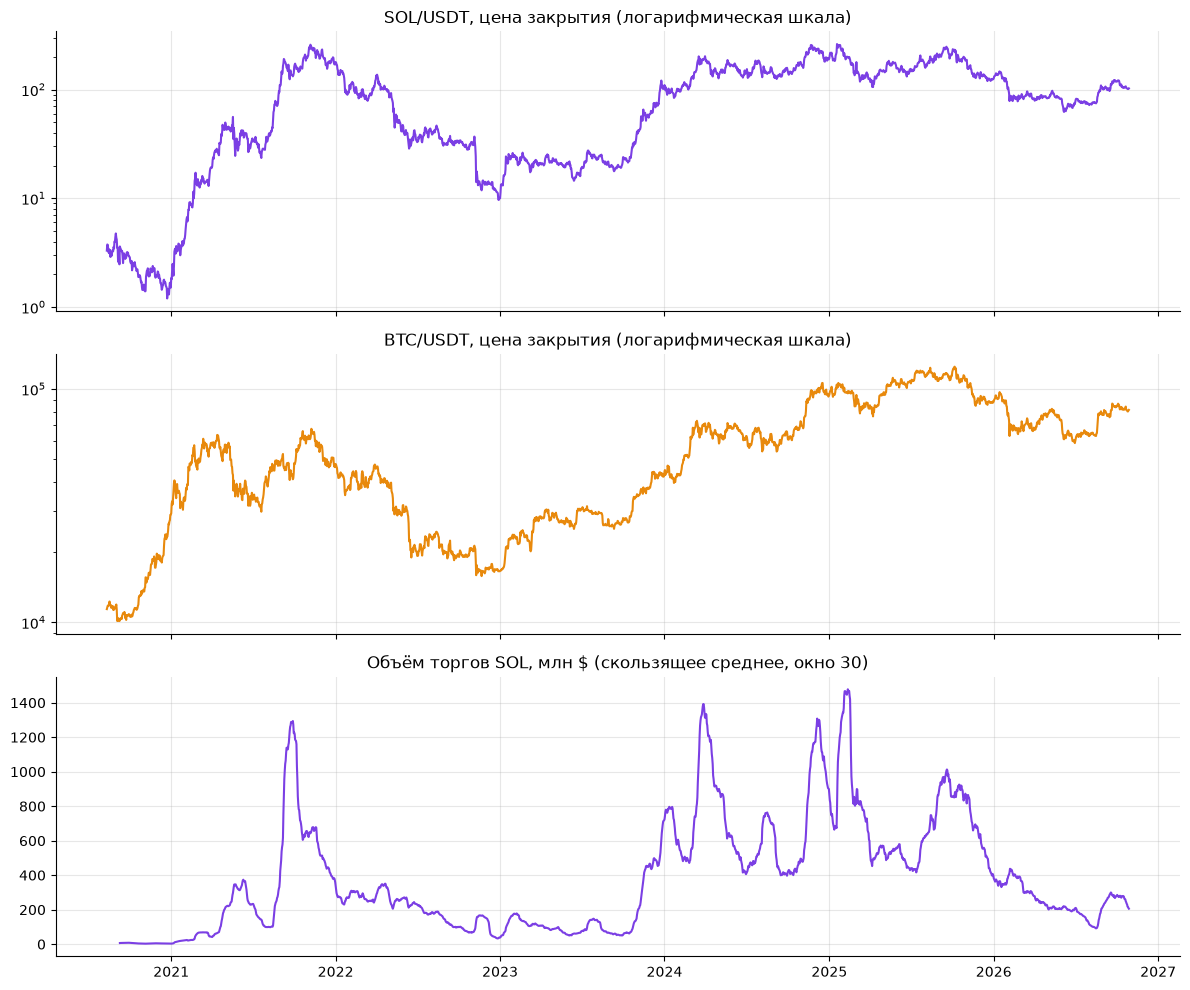

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(sol["close"], color=COLORS["sol"])
axes[0].set_yscale("log")
axes[0].set_title("SOL/USDT, цена закрытия (логарифмическая шкала)")

axes[1].plot(btc["close"], color=COLORS["btc"])
axes[1].set_yscale("log")
axes[1].set_title("BTC/USDT, цена закрытия (логарифмическая шкала)")

axes[2].plot(usd_volume(sol).rolling(ROLL).mean() / 1e6, color=COLORS["sol"])
axes[2].set_title(f"Объём торгов SOL, млн $ (скользящее среднее, окно {ROLL})")

plt.tight_layout()
plt.show()

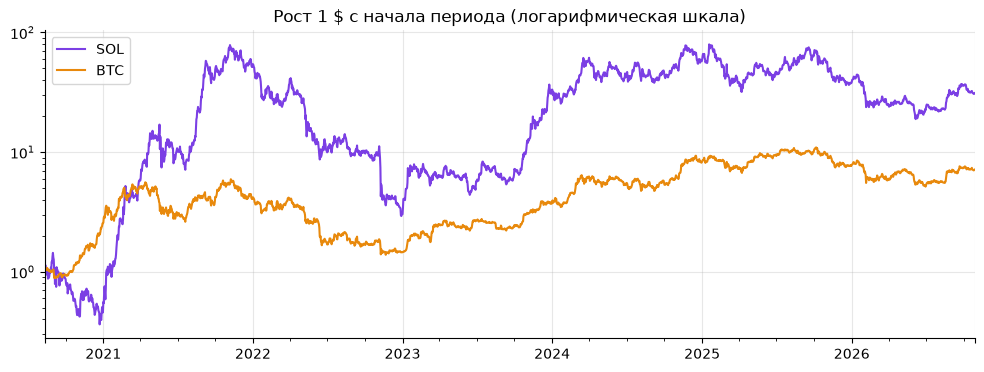

Максимальная просадка: {'SOL': '-96.3%', 'BTC': '-76.6%'}


In [5]:
# Рост 1 $, вложенного в начале периода
growth = pd.DataFrame({"SOL": sol["close"] / sol["close"].iloc[0],
                       "BTC": btc["close"] / btc["close"].iloc[0]})
ax = growth.plot(logy=True, color=[COLORS["sol"], COLORS["btc"]],
                 title="Рост 1 $ с начала периода (логарифмическая шкала)")
ax.set_xlabel("")
plt.show()

drawdown = growth / growth.cummax() - 1
print("Максимальная просадка:", drawdown.min().map("{:.1%}".format).to_dict())

**Вывод.** На графиках чётко видны фазы рынка: взрывной рост SOL в 2021 году (примерно с $3 до $260), обвал 2022 года (крах Terra/LUNA в мае и биржи FTX в ноябре), восстановление в 2023–2024 годах. Максимальная просадка от пика составила **−96.3% у SOL** и −76.6% у BTC: SOL — существенно более рискованный актив. Цена менялась почти на два порядка, поэтому дальше работаем с логарифмами и доходностями, а не с ценой.

## 3. Доходности и их распределение

Используем логарифмическую доходность $r_t = \ln(P_t / P_{t-1})$: она аддитивна во времени (доходность за $h$ дней равна сумме дневных) и симметричнее простой доходности.

In [6]:
ret = pd.DataFrame({"sol": np.log(sol["close"]).diff(),
                    "btc": np.log(btc["close"]).diff()}).dropna()


def describe_returns(r: pd.Series) -> pd.Series:
    sigma = r.std()
    return pd.Series({
        "среднее": r.mean(),
        "медиана": r.median(),
        "ст. отклонение": sigma,
        "годовая волатильность": sigma * np.sqrt(PERIODS_PER_YEAR),
        "асимметрия": stats.skew(r),
        "эксцесс (excess)": stats.kurtosis(r),
        "минимум": r.min(),
        "максимум": r.max(),
        "доля |r| > 3σ": (r.abs() > 3 * sigma).mean(),
        "то же у нормального": 2 * stats.norm.sf(3),
        "доля положительных": (r > 0).mean(),
        "Жарк–Бера, p-value": stats.jarque_bera(r).pvalue,
    })


ret_stats = ret.apply(describe_returns).rename(columns=str.upper)
ret_stats

,SOL,BTC
среднее,0.0015,0.0009
медиана,-0.0003,0.0002
ст. отклонение,0.0592,0.0297
годовая волатильность,1.1302,0.5679
асимметрия,-0.2099,-0.1140
эксцесс (excess),8.4857,4.0466
минимум,-0.5490,-0.1670
максимум,0.3776,0.1784
доля |r| > 3σ,0.0141,0.0207
то же у нормального,0.0027,0.0027


In [7]:
# Самые сильные движения SOL — полезно сопоставить с новостями
top = ret["sol"].abs().nlargest(10).index
pd.DataFrame({"SOL": ret.loc[top, "sol"], "BTC": ret.loc[top, "btc"]}).sort_index()

,SOL,BTC
timestamp,,
2020-09-05 00:00:00+00:00,-0.3038,-0.0271
2020-09-09 00:00:00+00:00,0.3776,0.0091
2020-11-06 00:00:00+00:00,0.3049,-0.0006
2021-01-08 00:00:00+00:00,0.3097,0.0288
2021-02-22 00:00:00+00:00,0.2638,-0.0596
2021-05-19 00:00:00+00:00,-0.4699,-0.1552
2021-06-21 00:00:00+00:00,-0.2821,-0.1189
2022-05-11 00:00:00+00:00,-0.2733,-0.0637
2022-11-09 00:00:00+00:00,-0.5490,-0.1526


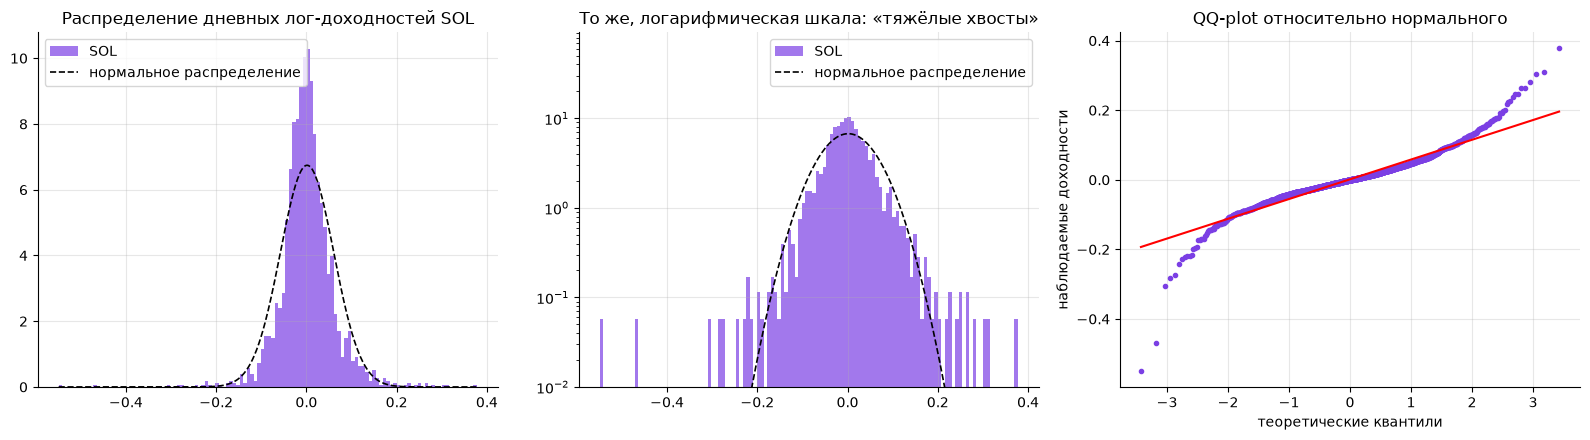

In [8]:
r = ret["sol"]
x = np.linspace(r.min(), r.max(), 400)
normal_pdf = stats.norm.pdf(x, r.mean(), r.std())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, log_scale in zip(axes[:2], [False, True]):
    ax.hist(r, bins=120, density=True, color=COLORS["sol"], alpha=0.7, label="SOL")
    ax.plot(x, normal_pdf, "k--", lw=1.2, label="нормальное распределение")
    ax.legend()
    if log_scale:
        ax.set_yscale("log")
        ax.set_ylim(bottom=1e-2)
axes[0].set_title("Распределение дневных лог-доходностей SOL")
axes[1].set_title("То же, логарифмическая шкала: «тяжёлые хвосты»")

stats.probplot(r, dist="norm", plot=axes[2])
axes[2].get_lines()[0].set(color=COLORS["sol"], markersize=3)
axes[2].set_title("QQ-plot относительно нормального")
axes[2].set_xlabel("теоретические квантили")
axes[2].set_ylabel("наблюдаемые доходности")
plt.tight_layout()
plt.show()

**Вывод.**
- Годовая волатильность SOL — **113%**, почти вдвое выше, чем у BTC (57%). Дневное стандартное отклонение ≈ 5.9% против 3.0%.
- Распределение далеко от нормального: **эксцесс 8.5** у SOL (4.0 у BTC), тест Жарка–Бера уверенно отвергает нормальность (p ≈ 0). Движения больше 3σ у SOL случаются в 1.4% дней, это **в ~5 раз чаще**, чем у нормального распределения (0.27%).
- Асимметрия слабо отрицательная (−0.21): сильнейшие падения глубже сильнейших взлётов (минимум −55%, максимум +38% за день).
- Средняя дневная доходность (0.15%) в ~40 раз меньше стандартного отклонения, доля растущих дней почти ровно 50%. Угадать знак завтрашней доходности по одной лишь статистике нельзя.
- Крупнейшие движения SOL совпадают с известными событиями: 19.05.2021 (обвал рынка после запрета финансовым организациям Китая работать с криптовалютой, −47%), 21.06.2021 (запрет майнинга в Китае, −28%), 11.05.2022 (крах Terra/LUNA, −27%), **09.11.2022 (крах FTX, −55%)**, 14.01.2023 (отскок после FTX, +28%). Часть экстремальных дней 2020–2021 годов (например, +38% 09.09.2020) случилась при почти неподвижном BTC: это собственные события SOL на фоне низкой ликвидности после листинга.

**Следствие для модели:** MSE будет перекошена редкими экстремальными днями, поэтому вместе с ней смотрим MAE / Huber loss и точность направления. Стоит проверить устойчивость результатов к исключению 2020 года (период низкой ликвидности).

## 4. Стационарность

Тест Дики–Фуллера (ADF): нулевая гипотеза — у ряда есть единичный корень, то есть ряд нестационарен. Если p-value < 0.05, гипотезу отвергаем.

In [9]:
series = {
    "log-цена SOL": np.log(sol["close"]),
    "log-цена BTC": np.log(btc["close"]),
    "доходность SOL": ret["sol"],
    "доходность BTC": ret["btc"],
}
rows = {}
for name, s in series.items():
    adf_stat, p_value, *_ = adfuller(s.dropna(), autolag="AIC")
    rows[name] = {"ADF-статистика": adf_stat, "p-value": p_value, "стационарен": p_value < 0.05}
adf_table = pd.DataFrame(rows).T
adf_table

/var/folders/ny/qv_d9jxd46347m7bj9qd9s200000gn/T/ipykernel_1476/2458033451.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_value, *_ = adfuller(s.dropna(), autolag="AIC")
/var/folders/ny/qv_d9jxd46347m7bj9qd9s200000gn/T/ipykernel_1476/2458033451.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_value, *_ = adfuller(s.dropna(), autolag="AIC")


,ADF-статистика,p-value,стационарен
log-цена SOL,-2.3634,0.1523,False
log-цена BTC,-2.0784,0.2533,False
доходность SOL,-49.8743,0.0000,True
доходность BTC,-49.1791,0.0000,True


**Вывод.** Лог-цена нестационарна: p-value 0.15 у SOL и 0.25 у BTC, гипотезу о единичном корне отвергнуть нельзя. Доходность стационарна: ADF-статистика ≈ −50, p-value ≈ 0. Это формальное обоснование выбора целевой переменной: **прогнозируем доходность, а не цену**. Модель, обученная на цене, легко покажет «хорошее» качество, просто повторяя вчерашнее значение.

## 5. Автокорреляция и кластеризация волатильности

Смотрим автокорреляцию (ACF) самих доходностей и их квадратов. Пунктир — граница значимости ±1.96/√n. Тест Льюнга–Бокса проверяет, что автокорреляции до лага $h$ одновременно равны нулю.

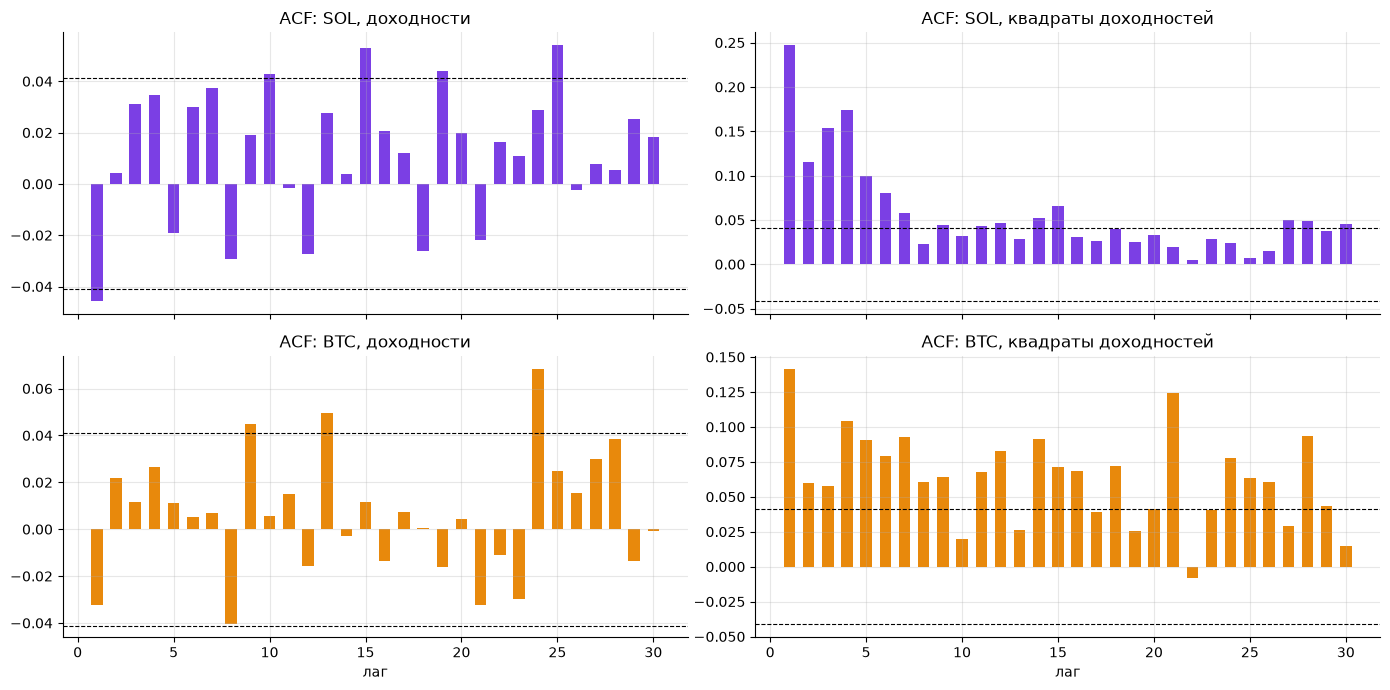

Льюнг–Бокс, p-value:


,SOL: r,SOL: r²,BTC: r,BTC: r²
лаг 5,0.0613,0.0000,0.3394,0.0000
лаг 10,0.0116,0.0000,0.1624,0.0000
лаг 20,0.0038,0.0000,0.3187,0.0000


In [10]:
NLAGS = 30


def acf(x, nlags: int) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    denom = np.dot(x, x)
    return np.array([np.dot(x[k:], x[:len(x) - k]) / denom for k in range(1, nlags + 1)])


def ljung_box_pvalue(x, h: int) -> float:
    n = len(x)
    rho = acf(x, h)
    q = n * (n + 2) * np.sum(rho ** 2 / (n - np.arange(1, h + 1)))
    return stats.chi2.sf(q, h)


fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for row, asset in enumerate(["sol", "btc"]):
    for col, (label, data) in enumerate([("доходности", ret[asset]), ("квадраты доходностей", ret[asset] ** 2)]):
        ax = axes[row, col]
        band = 1.96 / np.sqrt(len(data))
        ax.bar(range(1, NLAGS + 1), acf(data, NLAGS), color=COLORS[asset], width=0.6)
        ax.axhline(band, color="k", ls="--", lw=0.8)
        ax.axhline(-band, color="k", ls="--", lw=0.8)
        ax.set_title(f"ACF: {asset.upper()}, {label}")
axes[1, 0].set_xlabel("лаг")
axes[1, 1].set_xlabel("лаг")
plt.tight_layout()
plt.show()

lb = pd.DataFrame({
    f"{asset.upper()}: {label}": {f"лаг {h}": ljung_box_pvalue(data, h) for h in (5, 10, 20)}
    for asset in ["sol", "btc"]
    for label, data in [("r", ret[asset]), ("r²", ret[asset] ** 2)]
})
print("Льюнг–Бокс, p-value:")
lb

**Вывод.**
- **Квадраты доходностей** сильно автокоррелированы у обеих монет (Льюнг–Бокс, p ≈ 0 на всех лагах): это **кластеризация волатильности**, бурные дни идут сериями.
- **Сами доходности BTC** автокорреляции не имеют (p = 0.16–0.34), то есть по прошлому линейно не предсказываются.
- **У SOL** автокорреляция доходностей слабая, но статистически значимая на длинных лагах (p = 0.012 для 10 лагов, 0.004 для 20). Автокорреляция на лаге 1 равна −0.046, что чуть выходит за границу ±0.041: это намёк на слабый откат после сильных дней. Эффект маленький, но означает, что SOL предсказуема по своему прошлому чуть лучше, чем BTC.

**Следствие для модели:** волатильность прогнозируется заметно лучше направления, поэтому признаки волатильности (скользящее стандартное отклонение, размах high–low, ATR) обязательны. Лаги собственной доходности SOL стоит включить в признаки, но ожидать от них многого не стоит. Модели сравниваем с бейзлайнами «нулевая доходность» и «завтра как сегодня».

## 6. Волатильность

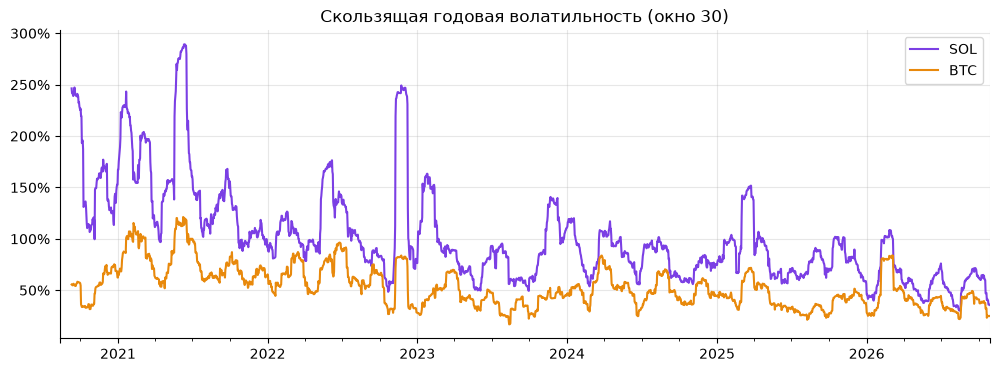

,SOL,BTC,SOL / BTC
год,,,
2020,1.6864,0.5612,3.0048
2021,1.6101,0.8093,1.9896
2022,1.2322,0.6441,1.9132
2023,0.9576,0.4357,2.1978
2024,0.8204,0.5268,1.5573
2025,0.8598,0.4167,2.0632
2026,0.6203,0.4455,1.3924


In [11]:
roll_vol = ret.rolling(ROLL).std() * np.sqrt(PERIODS_PER_YEAR)
ax = roll_vol.plot(color=[COLORS["sol"], COLORS["btc"]],
                   title=f"Скользящая годовая волатильность (окно {ROLL})")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(["SOL", "BTC"])
ax.set_xlabel("")
plt.show()

yearly_vol = ret.groupby(ret.index.year).agg(lambda r: r.std() * np.sqrt(PERIODS_PER_YEAR))
yearly_vol.columns = ["SOL", "BTC"]
yearly_vol["SOL / BTC"] = yearly_vol["SOL"] / yearly_vol["BTC"]
yearly_vol.index.name = "год"
yearly_vol

/var/folders/ny/qv_d9jxd46347m7bj9qd9s200000gn/T/ipykernel_1476/422062206.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  by_weekday = ret.groupby(ret.index.dayofweek).agg(["mean", "std"])


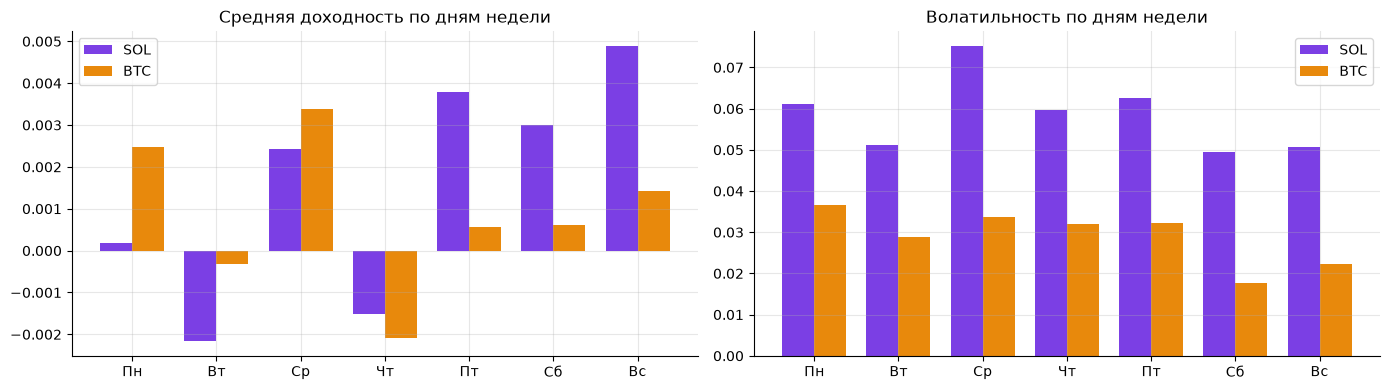

In [12]:
WEEKDAYS = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
by_weekday = ret.groupby(ret.index.day_of_week).agg(["mean", "std"])
by_weekday.index = WEEKDAYS

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
w = 0.38
xs = np.arange(7)
for i, asset in enumerate(["sol", "btc"]):
    axes[0].bar(xs + (i - 0.5) * w, by_weekday[(asset, "mean")], w, color=COLORS[asset], label=asset.upper())
    axes[1].bar(xs + (i - 0.5) * w, by_weekday[(asset, "std")], w, color=COLORS[asset], label=asset.upper())
for ax, title in zip(axes, ["Средняя доходность по дням недели", "Волатильность по дням недели"]):
    ax.set_xticks(xs, WEEKDAYS)
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

if INTERVAL != "1d":
    by_hour = ret.groupby(ret.index.hour).std()
    by_hour.plot(kind="bar", color=[COLORS["sol"], COLORS["btc"]],
                 title="Волатильность по часам (UTC)", figsize=(14, 4))
    plt.show()

**Вывод.**
- Волатильность SOL **снижается год от года**: 169% в 2020, 161% в 2021, 123% в 2022, 96% в 2023, 82% в 2024, 86% в 2025, 62% в 2026. Монета «взрослеет»: растут капитализация и ликвидность.
- Вместе с этим сокращается разрыв с BTC: в 2020 году SOL была в 3 раза волатильнее BTC, в 2026 — лишь в 1.4 раза.
- Есть **эффект выходных**: в субботу и воскресенье волатильность заметно ниже (у SOL 5.0% против 6.2% в будни, у BTC 2.0% против 3.3%; тест Левена, p < 10⁻⁶). При этом средняя доходность по дням недели статистически не различается (тест Краскела–Уоллиса, p = 0.31 у SOL и 0.43 у BTC).

**Следствие для модели:** признак «выходной / будний день» полезен для прогноза волатильности и размера движения, но не направления. Из-за смены режимов модель нужно проверять на нескольких периодах (walk-forward), а признаки волатильности лучше нормировать на текущий уровень.

## 7. Взаимосвязь SOL и BTC

Считаем корреляцию доходностей, бету SOL к BTC ($\beta = \mathrm{cov}(r_{SOL}, r_{BTC}) / \mathrm{var}(r_{BTC})$, на сколько процентов в среднем двигается SOL при движении BTC на 1%), их изменение во времени и проверяем, опережает ли BTC движение SOL.

Корреляция Пирсона:   0.590
Корреляция Спирмена:  0.644
Бета SOL к BTC:       1.17
Доля дисперсии SOL, объяснённая BTC (R²): 34.8%


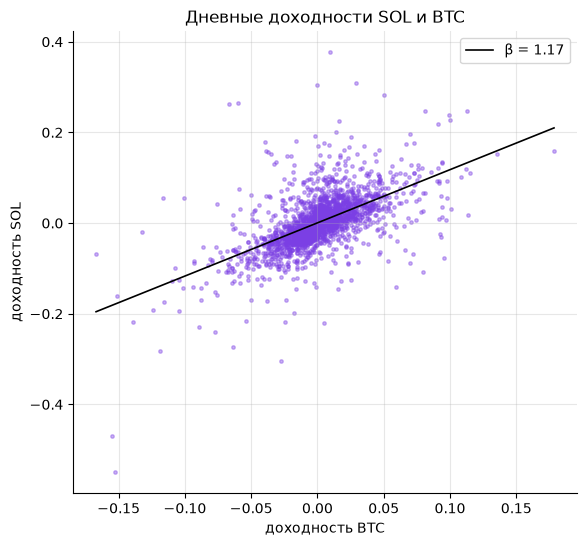

In [13]:
pearson = ret["sol"].corr(ret["btc"])
spearman = ret["sol"].corr(ret["btc"], method="spearman")
beta = ret["sol"].cov(ret["btc"]) / ret["btc"].var()
alpha = ret["sol"].mean() - beta * ret["btc"].mean()

print(f"Корреляция Пирсона:   {pearson:.3f}")
print(f"Корреляция Спирмена:  {spearman:.3f}")
print(f"Бета SOL к BTC:       {beta:.2f}")
print(f"Доля дисперсии SOL, объяснённая BTC (R²): {pearson ** 2:.1%}")

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(ret["btc"], ret["sol"], s=6, alpha=0.4, color=COLORS["sol"])
xx = np.linspace(ret["btc"].min(), ret["btc"].max(), 100)
ax.plot(xx, alpha + beta * xx, "k-", lw=1.2, label=f"β = {beta:.2f}")
ax.set_xlabel("доходность BTC")
ax.set_ylabel("доходность SOL")
ax.set_title("Дневные доходности SOL и BTC")
ax.legend()
plt.show()

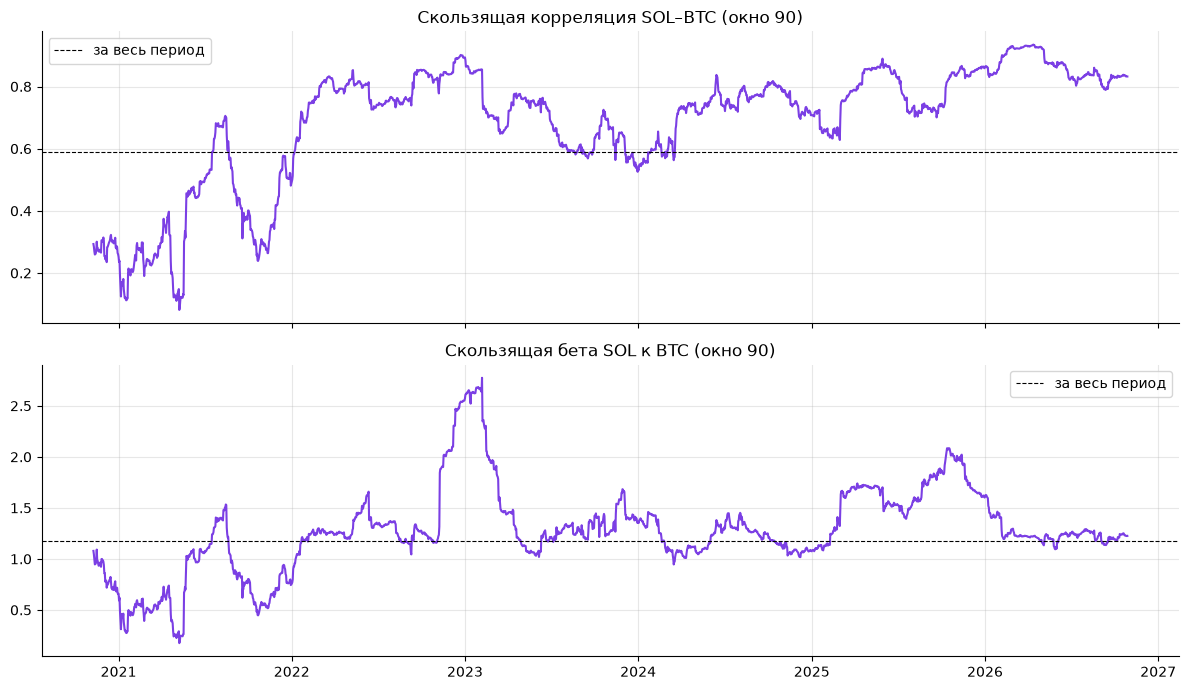

In [14]:
W = 3 * ROLL  # окно ≈ 90 дней
roll_corr = ret["sol"].rolling(W).corr(ret["btc"])
roll_beta = ret["sol"].rolling(W).cov(ret["btc"]) / ret["btc"].rolling(W).var()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(roll_corr, color=COLORS["sol"])
axes[0].axhline(pearson, color="k", ls="--", lw=0.8, label="за весь период")
axes[0].set_title(f"Скользящая корреляция SOL–BTC (окно {W})")
axes[0].legend()
axes[1].plot(roll_beta, color=COLORS["sol"])
axes[1].axhline(beta, color="k", ls="--", lw=0.8, label="за весь период")
axes[1].set_title(f"Скользящая бета SOL к BTC (окно {W})")
axes[1].legend()
plt.tight_layout()
plt.show()

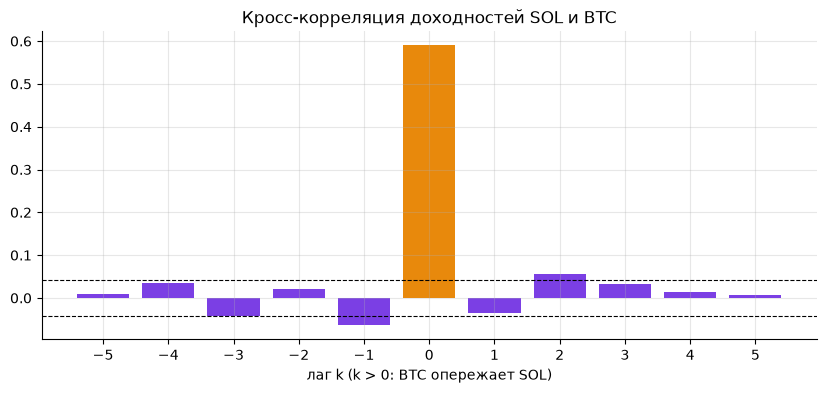

Граница значимости ±0.041


,"corr(SOL_{t+k}, BTC_t)","corr(SOL_{t+k}, SOL_t)"
горизонт k,,
1,-0.0354,-0.0456
2,0.0552,0.0041
3,0.0321,0.0312
4,0.0150,0.0349
5,0.0073,-0.0191


In [15]:
# Кросс-корреляция: corr(SOL_t, BTC_{t-k}).
# k > 0: BTC опережает SOL на k периодов (это и есть потенциально полезный признак),
# k < 0: SOL опережает BTC.
LAGS = range(-5, 6)
xcorr = pd.Series({k: ret["sol"].corr(ret["btc"].shift(k)) for k in LAGS})
band = 1.96 / np.sqrt(len(ret))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(xcorr.index, xcorr.values, color=[COLORS["btc"] if k == 0 else COLORS["sol"] for k in xcorr.index])
ax.axhline(band, color="k", ls="--", lw=0.8)
ax.axhline(-band, color="k", ls="--", lw=0.8)
ax.set_xticks(list(LAGS))
ax.set_xlabel("лаг k (k > 0: BTC опережает SOL)")
ax.set_title("Кросс-корреляция доходностей SOL и BTC")
plt.show()

lead = pd.DataFrame({
    "corr(SOL_{t+k}, BTC_t)": {k: ret["sol"].shift(-k).corr(ret["btc"]) for k in range(1, 6)},
    "corr(SOL_{t+k}, SOL_t)": {k: ret["sol"].shift(-k).corr(ret["sol"]) for k in range(1, 6)},
})
lead.index.name = "горизонт k"
print(f"Граница значимости ±{band:.3f}")
lead

**Вывод.**
- Связь SOL с BTC существенная, но далеко не полная: корреляция Пирсона **0.59** (Спирмена 0.64), BTC объясняет **~35%** дисперсии SOL, остальные 65% — собственные движения SOL.
- **Бета 1.17**: при движении BTC на 1% SOL в среднем двигается на 1.17% в ту же сторону.
- Связь **сильно усиливается со временем**: корреляция по годам 0.29 (2020) → 0.42 (2021) → 0.79 (2022) → 0.62 (2023) → 0.75 (2024) → 0.80 (2025) → 0.88 (2026). Скользящая 90-дневная корреляция менялась от 0.08 (май 2021) до 0.93 (апрель 2026), бета — от 0.18 до 2.77. Ранняя SOL жила своей жизнью, сейчас она движется почти синхронно с рынком.
- **Опережения почти нет**: вне нулевого лага все кросс-корреляции малы (|corr| ≤ 0.064). Вчерашний BTC не предсказывает завтрашний SOL: corr(SOL_t+1, BTC_t) = −0.035, это внутри границы ±0.041. Пограничные значения есть на лаге 2 (0.055) и лаге −1 (−0.064), но они маленькие и могут быть случайными при множественном сравнении.

**Следствие для модели:** признаки BTC полезны в первую очередь как описание рыночного режима (волатильность и тренд BTC, скользящая корреляция и бета), а не как прямой предиктор. Поскольку связь со временем меняется, скользящие корреляцию и бету стоит включить как признаки. Опережение BTC стоит перепроверить на часовых данных.

## 8. Итоги и выводы для моделирования

In [16]:
summary = pd.Series({
    "период": f"{ret.index.min():%Y-%m-%d} — {ret.index.max():%Y-%m-%d}",
    "наблюдений": len(ret),
    "годовая волатильность SOL": f"{ret_stats.loc['годовая волатильность', 'SOL']:.0%}",
    "годовая волатильность BTC": f"{ret_stats.loc['годовая волатильность', 'BTC']:.0%}",
    "эксцесс доходностей SOL": f"{ret_stats.loc['эксцесс (excess)', 'SOL']:.1f}",
    "p-value Жарка–Бера (SOL)": f"{ret_stats.loc['Жарк–Бера, p-value', 'SOL']:.2g}",
    "ADF p-value: log-цена SOL": f"{adf_table.loc['log-цена SOL', 'p-value']:.3f}",
    "ADF p-value: доходность SOL": f"{adf_table.loc['доходность SOL', 'p-value']:.2g}",
    "корреляция SOL–BTC": f"{pearson:.2f}",
    "бета SOL к BTC": f"{beta:.2f}",
    "corr(SOL_t+1, BTC_t)": f"{lead.iloc[0, 0]:.3f}",
    "corr(SOL_t+1, SOL_t)": f"{lead.iloc[0, 1]:.3f}",
})
summary.to_frame("значение")

,значение
период,2020-08-12 — 2026-10-28
наблюдений,2269
годовая волатильность SOL,113%
годовая волатильность BTC,57%
эксцесс доходностей SOL,8.5
p-value Жарка–Бера (SOL),0
ADF p-value: log-цена SOL,0.152
ADF p-value: доходность SOL,0
корреляция SOL–BTC,0.59
бета SOL к BTC,1.17


In [17]:
# Сохраняем лог-доходности для следующих этапов
PROCESSED.mkdir(parents=True, exist_ok=True)
ret.to_csv(PROCESSED / f"log_returns_{INTERVAL}.csv")
print("Сохранено:", PROCESSED / f"log_returns_{INTERVAL}.csv")

Сохранено: /Users/nikolajeliseev/Downloads/crypto-price-prediction/data/processed/log_returns_1d.csv


### Основные выводы

1. **Данные.** 2270 дневных свечей SOL/USDT и BTC/USDT с Binance (11.08.2020 — 28.10.2026), без пропусков и ошибок.
2. **Цель — доходность, а не цена.** Лог-цена нестационарна (ADF p = 0.15), лог-доходность стационарна (p ≈ 0).
3. **Высокий риск и тяжёлые хвосты.** Годовая волатильность SOL 113% (у BTC 57%), эксцесс 8.5, экстремальные дни в ~5 раз чаще нормального, максимальная просадка −96%. Нужны устойчивые к выбросам метрики.
4. **Направление предсказывать трудно.** Доля растущих дней ≈ 50%, автокорреляция доходностей SOL слабая (лаг 1: −0.046), у BTC её нет вовсе. Обязательно сравнение с наивными бейзлайнами.
5. **Волатильность предсказуема.** Сильная кластеризация волатильности (Льюнг–Бокс для r², p ≈ 0), эффект выходных (волатильность ниже на ~20–40%).
6. **Связь с BTC сильная, растущая, но без опережения.** Корреляция 0.59 за весь период (0.29 в 2020 → 0.88 в 2026), бета 1.17; вчерашний BTC не предсказывает завтрашний SOL.
7. **Смена режимов.** Волатильность SOL снижается год от года (169% → 62%), связь с BTC растёт. Модель надо валидировать на нескольких периодах, признаки — нормировать.

### План для чекпойнта 3

- **Целевая переменная:** лог-доходность SOL на горизонте $h$ (кандидаты: 1, 3 и 7 дней). Параллельно — бинарная задача «вырастет / упадёт».
- **Признаки:** лаги доходностей SOL и BTC, скользящая волатильность и размах high–low, объём и его изменение, скользящая корреляция и бета к BTC, признак выходного дня.
- **Валидация:** только по времени, без перемешивания (walk-forward / `TimeSeriesSplit`), признаки строятся строго из прошлого. Отдельно проверить качество без 2020 года.
- **Метрики:** MAE, RMSE, точность направления; бейзлайны — нулевая доходность, «завтра как сегодня», buy & hold.